In [44]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib

In [4]:
#load the main training application file
df_app = pd.read_csv('data/application_train.csv')

In [5]:
#inspect basic dimensions
print(f"Dataset Shape: {df_app.shape}")
print(f"Total Unique Loan Applications: {df_app['SK_ID_CURR'].nunique()}")

#Display target distribution
target_counts = df_app['TARGET'].value_counts(normalize=True)*100
print(f"\nTarget Class Distribution(%):\n{target_counts}")

Dataset Shape: (116457, 122)
Total Unique Loan Applications: 116457

Target Class Distribution(%):
TARGET
0    91.855363
1     8.144637
Name: proportion, dtype: float64


In [7]:
df_app.head(10)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,100008,0,Cash loans,M,N,Y,0,99000.0,490495.5,27517.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
6,100009,0,Cash loans,F,Y,Y,1,171000.0,1560726.0,41301.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,2.0
7,100010,0,Cash loans,M,Y,Y,0,360000.0,1530000.0,42075.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,100011,0,Cash loans,F,N,Y,0,112500.0,1019610.0,33826.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
9,100012,0,Revolving loans,M,N,Y,0,135000.0,405000.0,20250.0,...,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
df_app.shape

(116457, 122)

In [21]:
missing_count = df_app.isnull().sum()
missing_percentage = (missing_count / len(df_app)) * 100

#combine into a summary DataFrame
df_missing = pd.DataFrame({
    'Missing_Count': missing_count,
    'Missing_Percentage': missing_percentage
})

#filter and sort columns that have missing values, from highest to lowest
df_missing = df_missing[df_missing['Missing_Count'] > 0].sort_values(by='Missing_Percentage', ascending=False)

#display the top 15 columns with the most missing data
print("Top 15 Columns with Highest Missing Values: ")
print(df_missing.head(15))

#summary overview of missingness distribution
total_cols = df_app.shape[1]
cols_with_missing = len(df_missing)

print(f"\nTotal Columns: {total_cols}")
print(f"Columns with Zero Missing Values: {total_cols - cols_with_missing}")
print(f"Columns with > 50% Missing Values: {len(df_missing[df_missing['Missing_Percentage'] > 50])}")

Top 15 Columns with Highest Missing Values: 
                          Missing_Count  Missing_Percentage
COMMONAREA_MODE                   81327           69.834359
COMMONAREA_MEDI                   81327           69.834359
COMMONAREA_AVG                    81326           69.833501
NONLIVINGAPARTMENTS_MODE          80791           69.374104
NONLIVINGAPARTMENTS_MEDI          80791           69.374104
NONLIVINGAPARTMENTS_AVG           80791           69.374104
LIVINGAPARTMENTS_AVG              79592           68.344539
LIVINGAPARTMENTS_MEDI             79592           68.344539
LIVINGAPARTMENTS_MODE             79592           68.344539
FONDKAPREMONT_MODE                79536           68.296453
FLOORSMIN_MODE                    78941           67.785535
FLOORSMIN_AVG                     78941           67.785535
FLOORSMIN_MEDI                    78941           67.785535
YEARS_BUILD_MODE                  77368           66.434821
YEARS_BUILD_MEDI                  77368           66.43

## Relational Feature Engineering and Historical Aggregation

In [24]:
def agg_bureau(df_bureau,):
  #calculate basic numeric agg grouped by client ID
  bureau_agg = df_bureau.groupby('SK_ID_CURR').agg({
      'SK_ID_BUREAU': 'count',
      'DAYS_CREDIT': ['min', 'max', 'mean'],
      'CREDIT_DAY_OVERDUE': ['max', 'mean'],
      'AMT_CREDIT_SUM_DEBT': ['sum', 'mean'],
      'AMT_CREDIT_SUM': ['sum', 'mean', 'max'],
  })

  bureau_agg.columns = ['_'.join(col).upper() for col in bureau_agg.columns]
  bureau_agg = bureau_agg.reset_index()

  return bureau_agg

df_bureau = pd.read_csv('data/bureau.csv')
df_bureau_agg = agg_bureau(df_bureau)
df_bureau_agg.head()

,SK_ID_CURR,SK_ID_BUREAU_COUNT,DAYS_CREDIT_MIN,DAYS_CREDIT_MAX,DAYS_CREDIT_MEAN,CREDIT_DAY_OVERDUE_MAX,CREDIT_DAY_OVERDUE_MEAN,AMT_CREDIT_SUM_DEBT_SUM,AMT_CREDIT_SUM_DEBT_MEAN,AMT_CREDIT_SUM_SUM,AMT_CREDIT_SUM_MEAN,AMT_CREDIT_SUM_MAX
0,100001,7,-1572,-49,-735.000000,0,0.0,596686.5,85240.928571,1453365.000,207623.571429,378000.0
1,100002,8,-1437,-103,-874.000000,0,0.0,245781.0,49156.200000,865055.565,108131.945625,450000.0
2,100003,4,-2586,-606,-1400.750000,0,0.0,0.0,0.000000,1017400.500,254350.125000,810000.0
3,100004,2,-1326,-408,-867.000000,0,0.0,0.0,0.000000,189037.800,94518.900000,94537.8
4,100005,3,-373,-62,-190.666667,0,0.0,568408.5,189469.500000,657126.000,219042.000000,568800.0


In [26]:
#aggrigating previous applications
def agg_previous_applications(df_prev):
  #convert status flags/categorical metrics, then aggregate
  prev_agg = df_prev.groupby('SK_ID_CURR').agg({
      'SK_ID_PREV': 'count',
      'DAYS_DECISION': ['min', 'max', 'mean'],
      'AMT_ANNUITY': ['min', 'max', 'mean'],
      'AMT_APPLICATION': ['min', 'max'],
      'AMT_CREDIT': ['min', 'max', 'mean']
  })

  prev_agg.columns = ['PREV_' + '_'.join(col).upper() for col in prev_agg.columns]
  prev_agg = prev_agg.reset_index()

  return prev_agg

df_prev = pd.read_csv('data/previous_application.csv')
df_prev_agg = agg_previous_applications(df_prev)
df_prev_agg.head()

,SK_ID_CURR,PREV_SK_ID_PREV_COUNT,PREV_DAYS_DECISION_MIN,PREV_DAYS_DECISION_MAX,PREV_DAYS_DECISION_MEAN,PREV_AMT_ANNUITY_MIN,PREV_AMT_ANNUITY_MAX,PREV_AMT_ANNUITY_MEAN,PREV_AMT_APPLICATION_MIN,PREV_AMT_APPLICATION_MAX,PREV_AMT_CREDIT_MIN,PREV_AMT_CREDIT_MAX,PREV_AMT_CREDIT_MEAN
0,100001,1,-1740,-1740,-1740.0,3951.000,3951.000,3951.000,24835.5,24835.5,23787.0,23787.0,23787.00
1,100002,1,-606,-606,-606.0,9251.775,9251.775,9251.775,179055.0,179055.0,179055.0,179055.0,179055.00
2,100003,3,-2341,-746,-1305.0,6737.310,98356.995,56553.990,68809.5,900000.0,68053.5,1035882.0,484191.00
3,100004,1,-815,-815,-815.0,5357.250,5357.250,5357.250,24282.0,24282.0,20106.0,20106.0,20106.00
4,100005,2,-757,-315,-536.0,4813.200,4813.200,4813.200,0.0,44617.5,0.0,40153.5,20076.75


In [30]:
# merging the 3 datasets into the master training store using left join
def_master = df_app.merge(df_bureau_agg, on='SK_ID_CURR', how='left')
df_master = def_master.merge(df_prev_agg, on='SK_ID_CURR', how='left')

print(f"Master Feature Store Shape: {df_master.shape}")

Master Feature Store Shape: (116457, 145)


## Training the model

In [35]:
# separate feature (x) and target (y) from the master dataset
# drop ID and target from features
X = df_master.drop(columns=['SK_ID_CURR', 'TARGET'])
y = df_master['TARGET']

#identify all columns with object (text) data types
object_cols = X.select_dtypes(include=['object']).columns
print(f"Converting {len(object_cols)} object columns to category dtypes...")

#conveting the data types to pandas 'category' type
for col in object_cols:
  X[col] = X[col].astype('category')

#split data into train and validation sets (stratified to preserve class ratio)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

#initialize LightGBM classifier dataset structures
train_data = lgb.Dataset(X_train, label=y_train)
val_data = lgb.Dataset(X_val, label=y_val, reference=train_data)

#define model hyperparameters optimized for tabular credit risk
params = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    'n_estimators': 1000,
    'learning_rate': 0.03, # slows down the learning rate for better generalization
    'num_leaves': 20,
    'min_child_samples': 80, #the number of samples per leaf
    'reg_alpha': 0.1,
    'reg_lambda': 0.5,
    'random_state' : 42,
    'n_jobs': -1
}

#training the model with early stopping to prevent overfittig
model = lgb.train(
    params,
    train_data,
    valid_sets=[train_data, val_data],
    callbacks=[lgb.early_stopping(stopping_rounds=50), lgb.log_evaluation(100)]
)

#evaluate initial ROC-AUC on validation data
val_preds = model.predict(X_val, num_iteration=model.best_iteration)

#calculating advanced risk metrix
val_auc = roc_auc_score(y_val, val_preds)
val_gini = (2 * val_auc) - 1 #this is an industry standard gini coefficient formula
val_pr_auc = average_precision_score(y_val, val_preds)

print(f"\n---Model Evaluation---")
print(f"Validation Gini Coefficient: {val_gini:.4f}")
print(f"Validation ROC-AUC score: {val_auc:.4f}")
print(f"Validation PR-AUC: {val_pr_auc:.4f}")

Converting 16 object columns to category dtypes...
[LightGBM] [Info] Number of positive: 7588, number of negative: 85577
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.469633 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 16578
[LightGBM] [Info] Number of data points in the train set: 93165, number of used features: 133
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.081447 -> initscore=-2.422849
[LightGBM] [Info] Start training from score -2.422849
Training until validation scores don't improve for 50 rounds
[100]	training's auc: 0.776748	valid_1's auc: 0.750966
[200]	training's auc: 0.805049	valid_1's auc: 0.759729
[300]	training's auc: 0.825458	valid_1's auc: 0.763735
[400]	training's auc: 0.842736	valid_1's auc: 0.764215
[500]	training's auc: 0.857721	valid_1's auc: 0.765052
Early stopping, best iteration is:
[502]	training's au

##model interpretation, feature importance and explainability using SHAP

#### when customer applies for a loan and is rejected based on our ML model, it is important that the institution provides reason codes, a human-understandable explanation of why the adverse decision was made

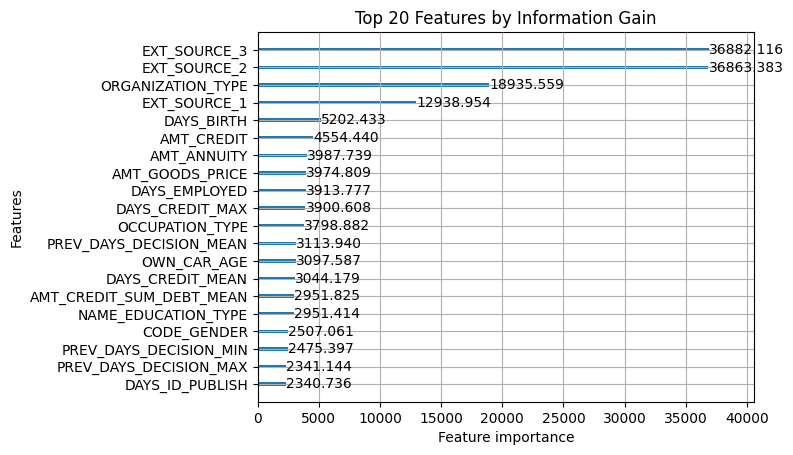

In [38]:
#inspecting which features the model relied on most heavily
#plotting LightGBM's built-in global feature importance
lgb.plot_importance(model, max_num_features=20, importance_type='gain')
plt.title("Top 20 Features by Information Gain")
plt.show()

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


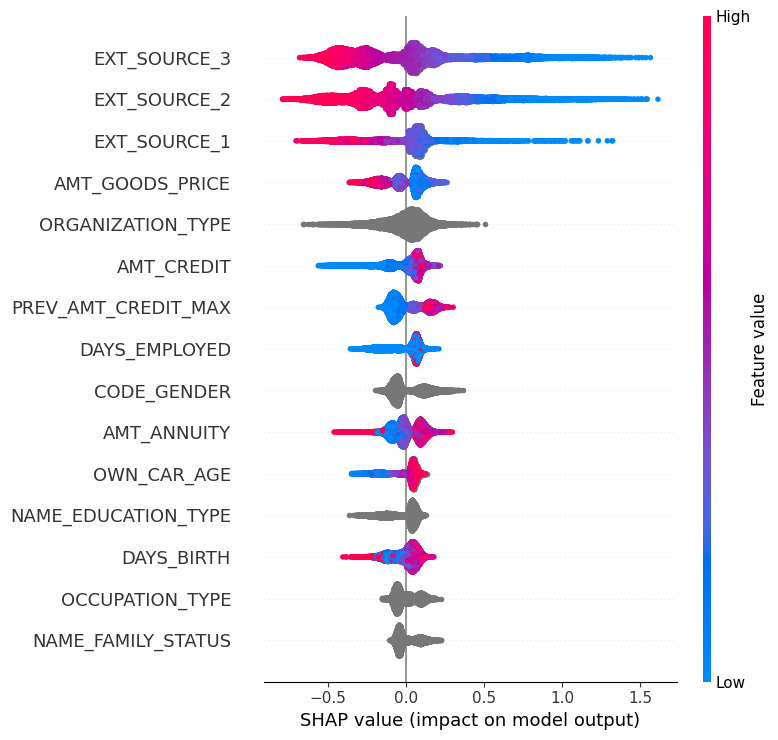

In [39]:
#calculating SHAP values for validation set using TreeExplainer
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_val)

if isinstance(shap_values, list):
  shap_vals_to_plot = shap_values[1]
else:
  shap_vals_to_plot = shap_values

shap.summary_plot(shap_vals_to_plot, X_val, max_display=15)

## Wrapping the model on a web app for deployment

In [42]:
# saving the trained model
joblib.dump(model, 'credit_risk_lgb_model.pkl')

#saving the feature columns so the app knows the exact schema
joblib.dump(list(X.columns), 'model_features.pkl')

#print("Model and feature columns successfully saved to disk!")


Model and feature columns successfully saved to disk!
